# FP32 DRAM roofline

Five Nsight profiles: uncapped constant memory and register caps of 96, 85, 80 and 75. Scene: 640 × 360, 64 threads/block, 16 threads/pixel.

**Best standalone: 80 registers, 29.059 ms.** Its profiling-session benchmark is 29.589 ms; its Nsight kernel duration is 34.624160 ms. Roofline coordinates use Nsight counters and duration.


In [1]:
import ncu_report

In [2]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
import matplotlib.pyplot as plt
plt.switch_backend("Agg")

PROJECT_ROOT = Path.cwd()  
ROOT = next((p for p in (PROJECT_ROOT, *PROJECT_ROOT.parents)
             if (p / "roofline_analysis.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing roofline_analysis.py and stats/")
sys.path.insert(0, str(ROOT))
from roofline_analysis import load_profiles, write_outputs
rows, peak_gbps = load_profiles(ROOT)
best = min(rows, key=lambda r: r["standalone_ms"])
print(f"Read {len(rows)} binary profiles; winner: {best['label']}")
print(f"Winner: profiling-session timing {best['benchmark_ms']:.3f} ms; "
      f"standalone {best['standalone_ms']:.3f} ms; Nsight kernel {best['profile_ms']:.6f} ms")

Read 5 binary profiles; winner: 80-register cap
Winner: profiling-session timing 29.589 ms; standalone 29.059 ms; Nsight kernel 34.624160 ms


## Profile comparison


In [3]:
columns = ["Profile", "Nsight ms", "Standalone ms", "TFLOP/s", "FLOP/byte", "Occupancy %"]
lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
for r in rows:
    label = r["label"] + (" **(best)**" if r is best else "")
    values = [label, f"{r['profile_ms']:.3f}", f"{r['standalone_ms']:.3f}",
              f"{r['achieved_tflops']:.3f}", f"{r['intensity']:.2f}", f"{r['occupancy_pct']:.2f}"]
    lines.append("| " + " | ".join(values) + " |")
display(Markdown("\n".join(lines)))


| Profile | Nsight ms | Standalone ms | TFLOP/s | FLOP/byte | Occupancy % |
|---|---|---|---|---|---|
| Constant memory (uncapped) | 43.913 | 33.740 | 1.040 | 2302.13 | 31.18 |
| 96-register cap | 37.850 | 31.672 | 1.207 | 2159.79 | 39.03 |
| 85-register cap | 37.935 | 31.662 | 1.204 | 414.84 | 39.02 |
| 80-register cap **(best)** | 34.624 | 29.059 | 1.319 | 146.73 | 46.84 |
| 75-register cap | 35.139 | 30.037 | 1.300 | 87.33 | 46.79 |

## Roofline

Each point uses its own Nsight counters and duration. The star marks the best standalone configuration; the roof uses median profiling clocks.


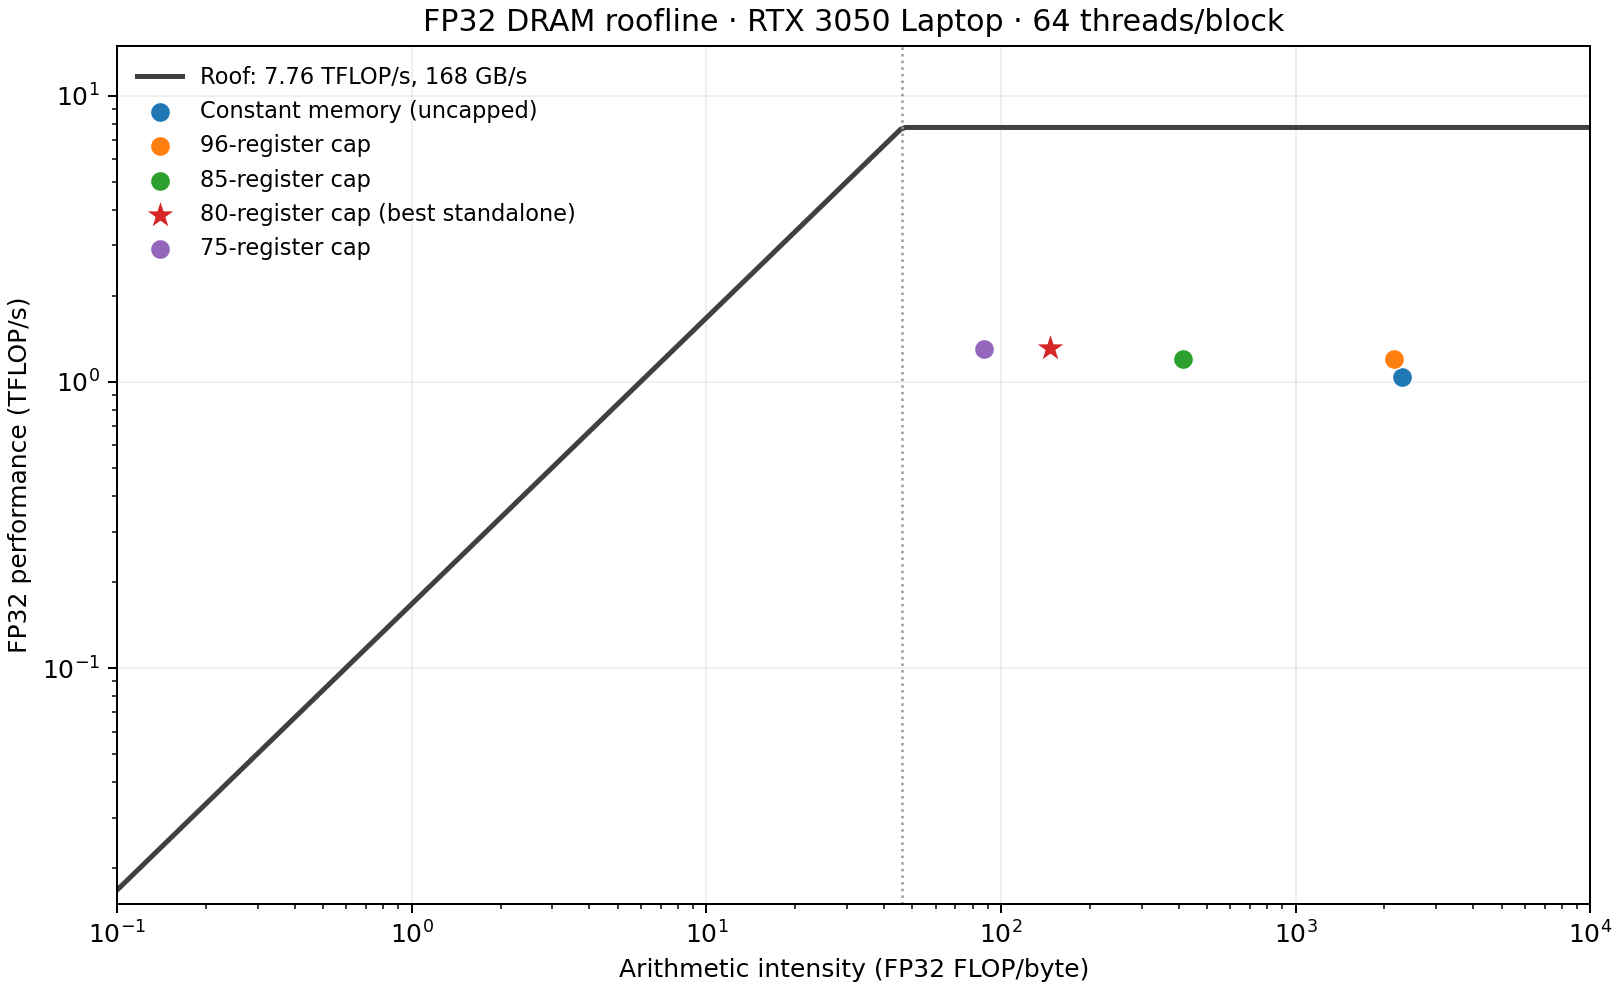

In [4]:
output = ROOT / "stats/reports"
write_outputs(rows, peak_gbps, output)
display(Image(filename=str(output / "roofline_profiles.png")))

## Interpretation

All points lie beyond the ridge, where the FP32 roof is lower than the DRAM roof. This does not prove arithmetic saturation: dependencies, divergence and scheduling can leave a gap.

The 80-register cap improves occupancy and timing over 96 and 85. At 75, occupancy barely changes while DRAM traffic and time increase, consistent with spilling.


In [5]:
display(Markdown(
    f"**80 registers:** {best['achieved_tflops']:.3f} TFLOP/s at "
    f"{best['intensity']:.2f} FLOP/byte; {best['roof_fraction_pct']:.2f}% of its roof."
))
assert len(rows) == 5 and len({r['source'] for r in rows}) == 5
assert best['config'] == '80_registers'
assert abs(best['profile_ms'] - 34.624160) < 1e-6
assert abs(best['benchmark_ms'] - 29.589) < 1e-6
assert abs(best['standalone_ms'] - 29.059) < 1e-6
for r in rows:
    assert r['intensity'] > r['fp32_peak_tflops'] * 1000 / r['dram_peak_gbps']
    assert 0 < r['roof_fraction_pct'] <= 100
    assert abs(r['work_gflop'] / r['profile_ms'] - r['achieved_tflops']) < 1e-10
    for field in ('source', 'timing_source', 'standalone_source'):
        assert (ROOT / r[field]).is_file()

**80 registers:** 1.319 TFLOP/s at 146.73 FLOP/byte; 17.01% of its roof.

## Inspect source metrics

Print the winning report’s input counters and units. The CSV records all profiles and their sources.


In [6]:
context = ncu_report.load_report(str(ROOT / best['source']))
action = context.range_by_idx(best['range_index']).action_by_idx(best['action_index'])
print("Kernel:", action.name())
for name in ("gpu__time_duration.avg", "smsp__cycles_elapsed.sum",
             "smsp__sass_thread_inst_executed_op_fadd_pred_on.avg.per_cycle_elapsed",
             "smsp__sass_thread_inst_executed_op_fmul_pred_on.avg.per_cycle_elapsed",
             "smsp__sass_thread_inst_executed_op_ffma_pred_on.avg.per_cycle_elapsed",
             "dram__bytes_read.sum", "dram__bytes_write.sum",
             "sm__sass_thread_inst_executed_op_ffma_pred_on.sum.peak_sustained",
             "sm__cycles_elapsed.avg.per_second", "dram__bytes.sum.peak_sustained",
             "dram__cycles_elapsed.avg.per_second"):
    metric = action.metric_by_name(name)
    print(f"{name}: {metric.value()} {metric.unit()}")

Kernel: render_kernel
gpu__time_duration.avg: 34624160.0 ns
smsp__cycles_elapsed.sum: 4195806880.0 cycle
smsp__sass_thread_inst_executed_op_fadd_pred_on.avg.per_cycle_elapsed: 0.9829318605340578 inst/cycle
smsp__sass_thread_inst_executed_op_fmul_pred_on.avg.per_cycle_elapsed: 1.4045752320230718 inst/cycle
smsp__sass_thread_inst_executed_op_ffma_pred_on.avg.per_cycle_elapsed: 4.250463658375049 inst/cycle
dram__bytes_read.sum: 37671808.0 byte
dram__bytes_write.sum: 273680384.0 byte
sm__sass_thread_inst_executed_op_ffma_pred_on.sum.peak_sustained: 2560.0 inst/cycle
sm__cycles_elapsed.avg.per_second: 1514768473.805574 hz
dram__bytes.sum.peak_sustained: 24.0 byte/cycle
dram__cycles_elapsed.avg.per_second: 6986999135.863512 hz
